# Ways to generate multigroup cross sections

<!-- index:description -->
Generate and compare OpenMC multigroup cross sections (MGXS) with `material_wise`, `stochastic_slab`, and `infinite_medium`, as preparation for a later Pac-Man FW-CADIS simulation.
<!-- /index:description -->

<!-- generated:structure -->
```text
Ways to generate multigroup cross sections
├── 1. Build the continuous-energy model
├── 2. Generate MGXS libraries
├── 3. Read the MGXS libraries
├── 4. Total and absorption cross sections
├── 5. P0 scattering matrices
├── 6. Sanity checks
├── 7. (n,tot) in concrete
├── 8. Reproducibility and convergence
│   └── 8.1 Independent-seed reproducibility at 20,000 particles per batch
├── 9. Additional bootstrap
└── 10. Reuse these libraries in FW-CADIS
```
<!-- /generated:structure -->

This notebook generates MGXS libraries for later use in FW-CADIS and compares their cross sections, computation times, statistical stability, independent-seed reproducibility, and additional bootstrapping.

Of the three `openmc.Model.convert_to_multigroup()` methods:

- **`material_wise`** runs continuous-energy transport in the original Pac-Man geometry; its flux-weighted cross sections therefore depend on that geometry and source. The geometry comes from `../3_geometry/pacman_geometry_csg.xml`.
- **`stochastic_slab`** is independent of the simulation geometry, as it uses a surrogate randomized slab geometry.
- **`infinite_medium`** is independent of the simulation geometry, as it uses independent homogeneous-medium calculations.

The latter two still depend on the material definitions, energy-group structure, and calculation inputs. The imported Pac-Man geometry also provides the spatial model for the additional bootstrapping demonstration.

## 1. Build the continuous-energy model

In [ ]:
import copy
import json
import os
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import openmc
import pandas as pd

from openmc_workbench_config import DATA_ROOT

# Make the OpenMC executable discoverable from the Jupyter kernel.
os.environ['PATH'] = (
    str(Path(sys.executable).parent) + os.pathsep + os.environ['PATH']
)

openmc.config['cross_sections'] = (
    DATA_ROOT / 'endf-b8.1' / 'cross_sections.xml'
)

GEOMETRY_FILE = Path('../3_geometry/pacman_geometry_csg.xml')
PNNL_FILE = DATA_ROOT / 'pnnl_v2.json'
OUTPUT_DIR = Path('1_1_ways_to_convert_to_multigroup_outputs').resolve()
MGXS_DIR = OUTPUT_DIR / 'mgxs'
MGXS_DIR.mkdir(parents=True, exist_ok=True)

# Change to True when ready to run.
GENERATE_MGXS = False
RUN_CONVERGENCE = False
GENERATE_BOOTSTRAP_WINDOWS = False
GENERATE_BOOTSTRAP_MGXS = False

In [ ]:
with PNNL_FILE.open() as file:
    pnnl = json.load(file)

materials_by_name = {}
for name in ('Concrete, Ordinary (NIST)', 'Air (dry, near sea level)'):
    entry = pnnl['materials'][name]
    mat = openmc.Material(name=name)
    for element, fraction in entry['elements'].items():
        mat.add_element(element, fraction, percent_type=pnnl['percent_type'])
    mat.set_density(pnnl['density_units'], entry['density'])
    materials_by_name[name] = mat

concrete = materials_by_name['Concrete, Ordinary (NIST)']
air = materials_by_name['Air (dry, near sea level)']
materials = openmc.Materials([concrete, air])

geometry = openmc.Geometry.from_xml(
    path=GEOMETRY_FILE,
    materials=openmc.Materials(),
)
cells = {cell.name: cell for cell in geometry.get_all_cells().values()}
cells['WALL_CSG'].fill = concrete
cells['OPEN_CSG'].fill = air
cells['LOWER_SLAB'].fill = concrete
cells['UPPER_SLAB'].fill = concrete

In [ ]:
settings = openmc.Settings()
settings.run_mode = 'fixed source'
settings.batches = 50
settings.particles = 20_000
settings.source = openmc.IndependentSource(
    space=openmc.stats.Point((0.0, 0.0, 0.0)),
    angle=openmc.stats.Isotropic(),
    energy=openmc.stats.Discrete([2.5e6], [1.0]),
    particle='neutron',
)

# Mesh from the completed bootstrap run, not a MGXS energy discretization.
MESH_DIMENSION = (28, 31, 6)
LOWER_LEFT = (-1400.0, -1550.0, -300.0)
UPPER_RIGHT = (1400.0, 1550.0, 300.0)

flux_mesh = openmc.RegularMesh(name='Global flux monitor')
flux_mesh.dimension = MESH_DIMENSION
flux_mesh.lower_left = LOWER_LEFT
flux_mesh.upper_right = UPPER_RIGHT

flux_tally = openmc.Tally(name='global_flux')
flux_tally.filters = [openmc.MeshFilter(flux_mesh)]
flux_tally.scores = ['flux']

ce_model = openmc.Model(
    geometry=geometry,
    materials=materials,
    settings=settings,
    tallies=openmc.Tallies([flux_tally]),
)

## 2. Generate MGXS libraries

Each method uses a separate copy of the CE model. The baseline MGXS libraries use 20,000 particles per batch and an explicit random seed so they can be compared with independently seeded runs in Section 8.

The generated HDF5 files are saved under `1_1_ways_to_convert_to_multigroup_outputs/mgxs/` for reuse by the later FW-CADIS notebook.

In [2]:
%%time
methods = ['material_wise', 'stochastic_slab', 'infinite_medium']
BASE_PARTICLES = 20_000
BASE_SEED = 1
timing_rows = []

if GENERATE_MGXS:
    for method in methods:
        rr_model = copy.deepcopy(ce_model)
        rr_model.tallies = openmc.Tallies()

        start = time.perf_counter()
        rr_model.convert_to_multigroup(
            method=method,
            mgxs_path=MGXS_DIR / f'mgxs_{method}.h5',
            overwrite_mgxs_library=True,
            particles=BASE_PARTICLES,
            seed=BASE_SEED,
        )
        timing_rows.append({
            'Method': method,
            'Particles per batch': BASE_PARTICLES,
            'Seed': BASE_SEED,
            'Wall time (s)': time.perf_counter() - start,
        })

if timing_rows:
    display(pd.DataFrame(timing_rows))

/home/idies/miniconda3/envs/openmc-mpi/lib/python3.14/site-packages/openmc/mixin.py:72: IDWarning: Another Filter instance already exists with id=59.
  warn(msg, IDWarning)
/home/idies/miniconda3/envs/openmc-mpi/lib/python3.14/site-packages/openmc/mixin.py:72: IDWarning: Another Filter instance already exists with id=3.
  warn(msg, IDWarning)
/home/idies/miniconda3/envs/openmc-mpi/lib/python3.14/site-packages/openmc/mixin.py:72: IDWarning: Another Filter instance already exists with id=12.
  warn(msg, IDWarning)


                                %%%%%%%%%%%%%%%
                           %%%%%%%%%%%%%%%%%%%%%%%%
                        %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                      %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                    %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                   %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                                    %%%%%%%%%%%%%%%%%%%%%%%%
                                     %%%%%%%%%%%%%%%%%%%%%%%%
                 ###############      %%%%%%%%%%%%%%%%%%%%%%%%
                ##################     %%%%%%%%%%%%%%%%%%%%%%%
                ###################     %%%%%%%%%%%%%%%%%%%%%%%
                ####################     %%%%%%%%%%%%%%%%%%%%%%
                #####################     %%%%%%%%%%%%%%%%%%%%%
                ######################     %%%%%%%%%%%%%%%%%%%%
                #######################     %%%%%%%%%%%%%%%%%%
                 #######################     %%%%%%%%%%%%%%%%%
                 #####################

/home/idies/miniconda3/envs/openmc-mpi/lib/python3.14/site-packages/openmc/mixin.py:72: IDWarning: Another Filter instance already exists with id=117.
  warn(msg, IDWarning)
/home/idies/miniconda3/envs/openmc-mpi/lib/python3.14/site-packages/openmc/mixin.py:72: IDWarning: Another Filter instance already exists with id=61.
  warn(msg, IDWarning)
/home/idies/miniconda3/envs/openmc-mpi/lib/python3.14/site-packages/openmc/mixin.py:72: IDWarning: Another Filter instance already exists with id=70.
  warn(msg, IDWarning)


                                %%%%%%%%%%%%%%%
                           %%%%%%%%%%%%%%%%%%%%%%%%
                        %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                      %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                    %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                   %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                                    %%%%%%%%%%%%%%%%%%%%%%%%
                                     %%%%%%%%%%%%%%%%%%%%%%%%
                 ###############      %%%%%%%%%%%%%%%%%%%%%%%%
                ##################     %%%%%%%%%%%%%%%%%%%%%%%
                ###################     %%%%%%%%%%%%%%%%%%%%%%%
                ####################     %%%%%%%%%%%%%%%%%%%%%%
                #####################     %%%%%%%%%%%%%%%%%%%%%
                ######################     %%%%%%%%%%%%%%%%%%%%
                #######################     %%%%%%%%%%%%%%%%%%
                 #######################     %%%%%%%%%%%%%%%%%
                 #####################

/home/idies/miniconda3/envs/openmc-mpi/lib/python3.14/site-packages/openmc/mixin.py:72: IDWarning: Another Filter instance already exists with id=118.
  warn(msg, IDWarning)
/home/idies/miniconda3/envs/openmc-mpi/lib/python3.14/site-packages/openmc/mixin.py:72: IDWarning: Another Filter instance already exists with id=119.
  warn(msg, IDWarning)
/home/idies/miniconda3/envs/openmc-mpi/lib/python3.14/site-packages/openmc/mixin.py:72: IDWarning: Another Filter instance already exists with id=128.
  warn(msg, IDWarning)


                                %%%%%%%%%%%%%%%
                           %%%%%%%%%%%%%%%%%%%%%%%%
                        %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                      %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                    %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                   %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                                    %%%%%%%%%%%%%%%%%%%%%%%%
                                     %%%%%%%%%%%%%%%%%%%%%%%%
                 ###############      %%%%%%%%%%%%%%%%%%%%%%%%
                ##################     %%%%%%%%%%%%%%%%%%%%%%%
                ###################     %%%%%%%%%%%%%%%%%%%%%%%
                ####################     %%%%%%%%%%%%%%%%%%%%%%
                #####################     %%%%%%%%%%%%%%%%%%%%%
                ######################     %%%%%%%%%%%%%%%%%%%%
                #######################     %%%%%%%%%%%%%%%%%%
                 #######################     %%%%%%%%%%%%%%%%%
                 #####################

/home/idies/miniconda3/envs/openmc-mpi/lib/python3.14/site-packages/openmc/mixin.py:72: IDWarning: Another Filter instance already exists with id=138.
  warn(msg, IDWarning)
/home/idies/miniconda3/envs/openmc-mpi/lib/python3.14/site-packages/openmc/mixin.py:72: IDWarning: Another Filter instance already exists with id=139.
  warn(msg, IDWarning)
/home/idies/miniconda3/envs/openmc-mpi/lib/python3.14/site-packages/openmc/mixin.py:72: IDWarning: Another Filter instance already exists with id=148.
  warn(msg, IDWarning)


                                %%%%%%%%%%%%%%%
                           %%%%%%%%%%%%%%%%%%%%%%%%
                        %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                      %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                    %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                   %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                                    %%%%%%%%%%%%%%%%%%%%%%%%
                                     %%%%%%%%%%%%%%%%%%%%%%%%
                 ###############      %%%%%%%%%%%%%%%%%%%%%%%%
                ##################     %%%%%%%%%%%%%%%%%%%%%%%
                ###################     %%%%%%%%%%%%%%%%%%%%%%%
                ####################     %%%%%%%%%%%%%%%%%%%%%%
                #####################     %%%%%%%%%%%%%%%%%%%%%
                ######################     %%%%%%%%%%%%%%%%%%%%
                #######################     %%%%%%%%%%%%%%%%%%
                 #######################     %%%%%%%%%%%%%%%%%
                 #####################

,Method,Particles per batch,Seed,Wall time (s)
0,material_wise,20000,1,99.399772
1,stochastic_slab,20000,1,177.567413
2,infinite_medium,20000,1,122.005054


CPU times: user 1.26 s, sys: 350 ms, total: 1.61 s
Wall time: 6min 39s


## 3. Read the MGXS libraries

OpenMC numbers the energy groups from high to low energy, whereas HDF5 stores the group boundaries in ascending order.

In [3]:
mglib, mgxs = {}, {}

for method in methods:
    mglib[method] = openmc.MGXSLibrary.from_hdf5(
        MGXS_DIR / f'mgxs_{method}.h5'
    )
    mgxs[method] = {xs.name: xs for xs in mglib[method].xsdatas}

ref_method = methods[0]
edges = mglib[ref_method].energy_groups.group_edges

for method in methods[1:]:
    assert np.array_equal(mglib[method].energy_groups.group_edges, edges)
    assert mgxs[method].keys() == mgxs[ref_method].keys()

df_groups = pd.DataFrame({
    'Group (high to low)': np.arange(1, len(edges)),
    'Lower energy (eV)': edges[:-1][::-1],
    'Upper energy (eV)': edges[1:][::-1],
})
display(df_groups)

,Group (high to low),Lower energy (eV),Upper energy (eV)
0,1,0.625,2.000000e+07
1,2,0.000,6.250000e-01


## 4. Total and absorption cross sections

Compare each material and energy group with `material_wise` as the reference. The percentage difference is undefined when the reference value is zero.

In [4]:
rows = []

for material in mgxs[ref_method]:
    for reaction in ('total', 'absorption'):
        row_values = {
            method: getattr(mgxs[method][material], reaction)[0]
            for method in methods
        }
        reference = row_values[ref_method]

        for g in range(len(reference)):
            row = {
                'Material': material,
                'Reaction': reaction,
                'Group': g + 1,
            }
            for method in methods:
                row[method] = row_values[method][g]
            for method in methods[1:]:
                row[f'{method} difference (%)'] = (
                    100 * (row_values[method][g] - reference[g]) / reference[g]
                    if reference[g] != 0 else np.nan
                )
            rows.append(row)

df_xs = pd.DataFrame(rows)
display(df_xs)

,Material,Reaction,Group,material_wise,stochastic_slab,infinite_medium,stochastic_slab difference (%),infinite_medium difference (%)
0,Air__dry__near_sea_level__2,total,1,0.000158,0.000209,0.000244,32.492617,55.000474
1,Air__dry__near_sea_level__2,total,2,0.000504,0.000505,0.000461,0.200346,-8.620284
2,Air__dry__near_sea_level__2,absorption,1,0.000004,0.000003,0.000002,-18.719815,-47.258911
3,Air__dry__near_sea_level__2,absorption,2,0.000063,0.000064,0.000030,1.137632,-52.155395
4,Concrete__Ordinary__NIST__1,total,1,0.541206,0.540343,0.540199,-0.159369,-0.186158
5,Concrete__Ordinary__NIST__1,total,2,1.115608,1.115664,1.115770,0.005084,0.014594
6,Concrete__Ordinary__NIST__1,absorption,1,0.000279,0.000306,0.000307,9.537341,9.789870
7,Concrete__Ordinary__NIST__1,absorption,2,0.013165,0.013168,0.013171,0.017034,0.042959


## 5. P0 scattering matrices

The first `[0]` selects the temperature dataset; `[:, :, 0]` selects the isotropic scattering moment. Rows correspond to incoming groups and columns to outgoing groups.

In [5]:
rows = []

for material in mgxs[ref_method]:
    scatter = {
        method: mgxs[method][material].scatter_matrix[0][:, :, 0]
        for method in methods
    }
    for g_in in range(scatter[ref_method].shape[0]):
        for g_out in range(scatter[ref_method].shape[1]):
            reference = scatter[ref_method][g_in, g_out]
            row = {
                'Material': material,
                'Incoming group': g_in + 1,
                'Outgoing group': g_out + 1,
            }
            for method in methods:
                row[method] = scatter[method][g_in, g_out]
            for method in methods[1:]:
                value = scatter[method][g_in, g_out]
                row[f'{method} difference (%)'] = (
                    100 * (value - reference) / reference
                    if reference != 0 else np.nan
                )
            rows.append(row)

df_scatter = pd.DataFrame(rows)
display(df_scatter)

,Material,Incoming group,Outgoing group,material_wise,stochastic_slab,infinite_medium,stochastic_slab difference (%),infinite_medium difference (%)
0,Air__dry__near_sea_level__2,1,1,1.528519e-04,2.041822e-04,0.000241,33.581739,57.684910
1,Air__dry__near_sea_level__2,1,2,9.717185e-07,1.604641e-06,0.000001,65.134384,40.000978
2,Air__dry__near_sea_level__2,2,1,7.569514e-08,5.307146e-08,0.000001,-29.887894,1696.901100
3,Air__dry__near_sea_level__2,2,2,4.409498e-04,4.412660e-04,0.000429,0.071694,-2.697487
4,Concrete__Ordinary__NIST__1,1,1,5.190422e-01,5.181906e-01,0.518042,-0.164070,-0.192640
5,Concrete__Ordinary__NIST__1,1,2,2.188443e-02,2.184687e-02,0.021850,-0.171642,-0.159576
6,Concrete__Ordinary__NIST__1,2,1,5.670283e-05,5.664599e-05,0.000055,-0.100251,-2.891006
7,Concrete__Ordinary__NIST__1,2,2,1.102386e+00,1.102440e+00,1.102544,0.004947,0.014405


## 6. Sanity checks

In [6]:
rows = []

for method in methods:
    for material, xs in mgxs[method].items():
        total = xs.total[0]
        absorption = xs.absorption[0]
        scatter = xs.scatter_matrix[0]

        rows.append({
            'Method': method,
            'Material': material,
            'Groups': len(total),
            'Scattering shape': str(scatter.shape),
            'All finite': (
                np.isfinite(total).all()
                and np.isfinite(absorption).all()
                and np.isfinite(scatter).all()
            ),
            'Nonfinite total': (~np.isfinite(total)).sum(),
            'Nonfinite absorption': (~np.isfinite(absorption)).sum(),
            'Nonfinite scattering': (~np.isfinite(scatter)).sum(),
            'Negative total': (total < 0).sum(),
            'Negative absorption': (absorption < 0).sum(),
            'Negative P0 scattering': (scatter[:, :, 0] < 0).sum(),
            'Zero total': (total == 0).sum(),
            'Zero absorption': (absorption == 0).sum(),
        })

df_diagnostics = pd.DataFrame(rows)
display(df_diagnostics)

,Method,Material,Groups,Scattering shape,All finite,Nonfinite total,Nonfinite absorption,Nonfinite scattering,Negative total,Negative absorption,Negative P0 scattering,Zero total,Zero absorption
0,material_wise,Air__dry__near_sea_level__2,2,"(2, 2, 1)",True,0,0,0,0,0,0,0,0
1,material_wise,Concrete__Ordinary__NIST__1,2,"(2, 2, 1)",True,0,0,0,0,0,0,0,0
2,stochastic_slab,Air__dry__near_sea_level__2,2,"(2, 2, 1)",True,0,0,0,0,0,0,0,0
3,stochastic_slab,Concrete__Ordinary__NIST__1,2,"(2, 2, 1)",True,0,0,0,0,0,0,0,0
4,infinite_medium,Air__dry__near_sea_level__2,2,"(2, 2, 1)",True,0,0,0,0,0,0,0,0
5,infinite_medium,Concrete__Ordinary__NIST__1,2,"(2, 2, 1)",True,0,0,0,0,0,0,0,0


## 7. (n,tot) in concrete

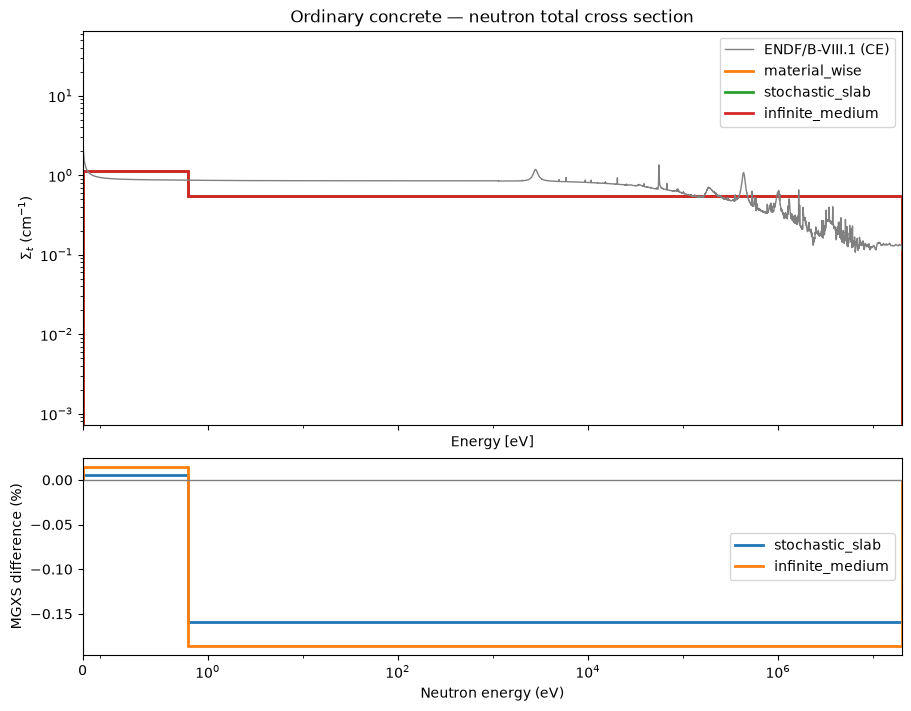

In [7]:
concrete_name = next(
    name for name in mgxs[ref_method] if 'Concrete' in name
)
# MGXS dataset names are normalized; CE material names are not.
concrete = next(
    mat for mat in ce_model.geometry.get_all_materials().values()
    if 'concrete' in mat.name.lower()
)
reference = mgxs[ref_method][concrete_name].total[0][::-1]

fig, (ax, ax_diff) = plt.subplots(
    2, 1, figsize=(9, 7), sharex=True,
    layout='constrained', height_ratios=[2, 1],
)

# CE cross sections are computed directly from the selected ENDF/B-VIII.1 data.
openmc.plot_xs(
    {concrete: ['total']},
    axis=ax,
    temperature=294.0,
    ce_cross_sections=str(openmc.config['cross_sections']),
)
ax.lines[-1].set(
    label='ENDF/B-VIII.1 (CE)', color='0.5', linewidth=1,
)

for method in methods:
    values = mgxs[method][concrete_name].total[0][::-1]
    ax.stairs(values, edges, label=method, linewidth=2)

    if method != ref_method:
        ax_diff.stairs(
            100 * (values - reference) / reference,
            edges,
            label=method,
            linewidth=2,
        )

ax.set(
    ylabel=r'$\Sigma_t$ (cm$^{-1}$)',
    title='Ordinary concrete — neutron total cross section',
)
ax.set_yscale('log')
ax.legend()

ax_diff.axhline(0, color='0.5', linewidth=1)
ax_diff.set(
    xlabel='Neutron energy (eV)',
    ylabel='MGXS difference (%)',
)
ax_diff.legend()
ax_diff.set_xscale('symlog', linthresh=0.625)
ax_diff.set_xlim(edges[0], edges[-1])
ax_diff.set_xticks([0, 1, 1e2, 1e4, 1e6])
plt.show()


## 8. Reproducibility and convergence

Generate independent MGXS libraries with increasing numbers of particles per batch and different random seeds. The 20,000-particle convergence run is an independent redo of the original 20,000-particle calculation, not a restart.

First, compare successive particle levels (20,000 → 40,000 → 80,000) as an indication of statistical stability. Then compare the two independent 20,000-particle results to examine run-to-run reproducibility at fixed statistics.

In [8]:
%%time
CONVERGENCE_METHODS = methods
CONVERGENCE_PARTICLES = [20_000, 40_000, 80_000]
CONVERGENCE_DIR = MGXS_DIR / 'convergence'
CONVERGENCE_DIR.mkdir(parents=True, exist_ok=True)

if RUN_CONVERGENCE:
    for method_index, method in enumerate(CONVERGENCE_METHODS):
        for level_index, particles in enumerate(CONVERGENCE_PARTICLES):
            path = CONVERGENCE_DIR / f'mgxs_{method}_{particles}.h5'
            model = copy.deepcopy(ce_model)
            model.tallies = openmc.Tallies()
            seed = 10_001 + 1000 * method_index + 137 * level_index

            model.convert_to_multigroup(
                method=method,
                mgxs_path=path,
                overwrite_mgxs_library=True,
                particles=particles,
                seed=seed,
            )

/home/idies/miniconda3/envs/openmc-mpi/lib/python3.14/site-packages/openmc/mixin.py:72: IDWarning: Another Filter instance already exists with id=215.
  warn(msg, IDWarning)
/home/idies/miniconda3/envs/openmc-mpi/lib/python3.14/site-packages/openmc/mixin.py:72: IDWarning: Another Filter instance already exists with id=159.
  warn(msg, IDWarning)
/home/idies/miniconda3/envs/openmc-mpi/lib/python3.14/site-packages/openmc/mixin.py:72: IDWarning: Another Filter instance already exists with id=168.
  warn(msg, IDWarning)


                                %%%%%%%%%%%%%%%
                           %%%%%%%%%%%%%%%%%%%%%%%%
                        %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                      %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                    %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                   %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                                    %%%%%%%%%%%%%%%%%%%%%%%%
                                     %%%%%%%%%%%%%%%%%%%%%%%%
                 ###############      %%%%%%%%%%%%%%%%%%%%%%%%
                ##################     %%%%%%%%%%%%%%%%%%%%%%%
                ###################     %%%%%%%%%%%%%%%%%%%%%%%
                ####################     %%%%%%%%%%%%%%%%%%%%%%
                #####################     %%%%%%%%%%%%%%%%%%%%%
                ######################     %%%%%%%%%%%%%%%%%%%%
                #######################     %%%%%%%%%%%%%%%%%%
                 #######################     %%%%%%%%%%%%%%%%%
                 #####################

/home/idies/miniconda3/envs/openmc-mpi/lib/python3.14/site-packages/openmc/mixin.py:72: IDWarning: Another Filter instance already exists with id=273.
  warn(msg, IDWarning)
/home/idies/miniconda3/envs/openmc-mpi/lib/python3.14/site-packages/openmc/mixin.py:72: IDWarning: Another Filter instance already exists with id=217.
  warn(msg, IDWarning)
/home/idies/miniconda3/envs/openmc-mpi/lib/python3.14/site-packages/openmc/mixin.py:72: IDWarning: Another Filter instance already exists with id=226.
  warn(msg, IDWarning)


                                %%%%%%%%%%%%%%%
                           %%%%%%%%%%%%%%%%%%%%%%%%
                        %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                      %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                    %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                   %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                                    %%%%%%%%%%%%%%%%%%%%%%%%
                                     %%%%%%%%%%%%%%%%%%%%%%%%
                 ###############      %%%%%%%%%%%%%%%%%%%%%%%%
                ##################     %%%%%%%%%%%%%%%%%%%%%%%
                ###################     %%%%%%%%%%%%%%%%%%%%%%%
                ####################     %%%%%%%%%%%%%%%%%%%%%%
                #####################     %%%%%%%%%%%%%%%%%%%%%
                ######################     %%%%%%%%%%%%%%%%%%%%
                #######################     %%%%%%%%%%%%%%%%%%
                 #######################     %%%%%%%%%%%%%%%%%
                 #####################

/home/idies/miniconda3/envs/openmc-mpi/lib/python3.14/site-packages/openmc/mixin.py:72: IDWarning: Another Filter instance already exists with id=331.
  warn(msg, IDWarning)
/home/idies/miniconda3/envs/openmc-mpi/lib/python3.14/site-packages/openmc/mixin.py:72: IDWarning: Another Filter instance already exists with id=275.
  warn(msg, IDWarning)
/home/idies/miniconda3/envs/openmc-mpi/lib/python3.14/site-packages/openmc/mixin.py:72: IDWarning: Another Filter instance already exists with id=284.
  warn(msg, IDWarning)


                                %%%%%%%%%%%%%%%
                           %%%%%%%%%%%%%%%%%%%%%%%%
                        %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                      %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                    %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                   %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                                    %%%%%%%%%%%%%%%%%%%%%%%%
                                     %%%%%%%%%%%%%%%%%%%%%%%%
                 ###############      %%%%%%%%%%%%%%%%%%%%%%%%
                ##################     %%%%%%%%%%%%%%%%%%%%%%%
                ###################     %%%%%%%%%%%%%%%%%%%%%%%
                ####################     %%%%%%%%%%%%%%%%%%%%%%
                #####################     %%%%%%%%%%%%%%%%%%%%%
                ######################     %%%%%%%%%%%%%%%%%%%%
                #######################     %%%%%%%%%%%%%%%%%%
                 #######################     %%%%%%%%%%%%%%%%%
                 #####################

... (14 outputs left out)

/home/idies/miniconda3/envs/openmc-mpi/lib/python3.14/site-packages/openmc/mixin.py:72: IDWarning: Another Filter instance already exists with id=586.
  warn(msg, IDWarning)
/home/idies/miniconda3/envs/openmc-mpi/lib/python3.14/site-packages/openmc/mixin.py:72: IDWarning: Another Filter instance already exists with id=587.
  warn(msg, IDWarning)
/home/idies/miniconda3/envs/openmc-mpi/lib/python3.14/site-packages/openmc/mixin.py:72: IDWarning: Another Filter instance already exists with id=596.
  warn(msg, IDWarning)


                                %%%%%%%%%%%%%%%
                           %%%%%%%%%%%%%%%%%%%%%%%%
                        %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                      %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                    %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                   %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                                    %%%%%%%%%%%%%%%%%%%%%%%%
                                     %%%%%%%%%%%%%%%%%%%%%%%%
                 ###############      %%%%%%%%%%%%%%%%%%%%%%%%
                ##################     %%%%%%%%%%%%%%%%%%%%%%%
                ###################     %%%%%%%%%%%%%%%%%%%%%%%
                ####################     %%%%%%%%%%%%%%%%%%%%%%
                #####################     %%%%%%%%%%%%%%%%%%%%%
                ######################     %%%%%%%%%%%%%%%%%%%%
                #######################     %%%%%%%%%%%%%%%%%%
                 #######################     %%%%%%%%%%%%%%%%%
                 #####################

/home/idies/miniconda3/envs/openmc-mpi/lib/python3.14/site-packages/openmc/mixin.py:72: IDWarning: Another Filter instance already exists with id=606.
  warn(msg, IDWarning)
/home/idies/miniconda3/envs/openmc-mpi/lib/python3.14/site-packages/openmc/mixin.py:72: IDWarning: Another Filter instance already exists with id=607.
  warn(msg, IDWarning)
/home/idies/miniconda3/envs/openmc-mpi/lib/python3.14/site-packages/openmc/mixin.py:72: IDWarning: Another Filter instance already exists with id=616.
  warn(msg, IDWarning)


                                %%%%%%%%%%%%%%%
                           %%%%%%%%%%%%%%%%%%%%%%%%
                        %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                      %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                    %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                   %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                                    %%%%%%%%%%%%%%%%%%%%%%%%
                                     %%%%%%%%%%%%%%%%%%%%%%%%
                 ###############      %%%%%%%%%%%%%%%%%%%%%%%%
                ##################     %%%%%%%%%%%%%%%%%%%%%%%
                ###################     %%%%%%%%%%%%%%%%%%%%%%%
                ####################     %%%%%%%%%%%%%%%%%%%%%%
                #####################     %%%%%%%%%%%%%%%%%%%%%
                ######################     %%%%%%%%%%%%%%%%%%%%
                #######################     %%%%%%%%%%%%%%%%%%
                 #######################     %%%%%%%%%%%%%%%%%
                 #####################

In [9]:
# Statistical stability: compare adjacent particle levels for each cross section.
# Percent changes with a near-zero higher-statistics value are left undefined.
MIN_REFERENCE_XS = 1e-6  # cm^-1
rows = []

for method in CONVERGENCE_METHODS:
    files = {
        n: CONVERGENCE_DIR / f'mgxs_{method}_{n}.h5'
        for n in CONVERGENCE_PARTICLES
    }
    if not all(path.exists() for path in files.values()):
        continue

    libs = {
        n: openmc.MGXSLibrary.from_hdf5(path)
        for n, path in files.items()
    }
    for lib in libs.values():
        assert np.array_equal(lib.energy_groups.group_edges, edges)

    xs_sets = {
        n: {xs.name: xs for xs in lib.xsdatas}
        for n, lib in libs.items()
    }

    for low_n, high_n in zip(CONVERGENCE_PARTICLES[:-1],
                             CONVERGENCE_PARTICLES[1:]):
        assert xs_sets[low_n].keys() == xs_sets[high_n].keys()
        for material in xs_sets[low_n]:
            for quantity in ('total', 'absorption', 'P0 scattering'):
                xs_low = xs_sets[low_n][material]
                xs_high = xs_sets[high_n][material]
                if quantity == 'P0 scattering':
                    low = xs_low.scatter_matrix[0][:, :, 0].ravel()
                    high = xs_high.scatter_matrix[0][:, :, 0].ravel()
                else:
                    low = getattr(xs_low, quantity)[0]
                    high = getattr(xs_high, quantity)[0]
                num_groups = len(xs_sets[low_n][material].total[0])

                for i, (a, b) in enumerate(zip(low, high)):
                    rows.append({
                        'Method': method,
                        'Material': material,
                        'Quantity': quantity,
                        'Particles (low)': low_n,
                        'Particles (high)': high_n,
                        'Incoming group': (i // num_groups + 1
                                           if quantity == 'P0 scattering'
                                           else i + 1),
                        'Outgoing group': (i % num_groups + 1
                                           if quantity == 'P0 scattering'
                                           else np.nan),
                        'Low value (cm^-1)': a,
                        'High value (cm^-1)': b,
                        'Absolute change (cm^-1)': abs(b - a),
                        'Relative change (%)': (
                            100 * abs(b - a) / abs(b)
                            if abs(b) >= MIN_REFERENCE_XS else np.nan
                        ),
                    })

df_convergence = pd.DataFrame(rows)
if not df_convergence.empty:
    df_convergence_summary = (
        df_convergence.groupby(
            ['Method', 'Material', 'Quantity',
             'Particles (low)', 'Particles (high)'],
            as_index=False,
        ).agg(
            Max_absolute_change=('Absolute change (cm^-1)', 'max'),
            Max_relative_change_percent=('Relative change (%)', 'max'),
            Median_relative_change_percent=('Relative change (%)', 'median'),
            Count_with_relative_change=('Relative change (%)', 'count'),
        )
    )
    display(df_convergence_summary)
    display(df_convergence)

,Method,Material,Quantity,Particles (low),Particles (high),Max_absolute_change,Max_relative_change_percent,Median_relative_change_percent,Count_with_relative_change
0,infinite_medium,Air__dry__near_sea_level__2,P0 scattering,20000,40000,4.996890e-08,0.600597,0.036311,4
1,infinite_medium,Air__dry__near_sea_level__2,P0 scattering,40000,80000,3.660874e-08,0.456335,0.021686,4
2,infinite_medium,Air__dry__near_sea_level__2,absorption,20000,40000,1.096002e-08,0.052395,0.044378,2
3,infinite_medium,Air__dry__near_sea_level__2,absorption,40000,80000,3.283483e-09,0.028017,0.019456,2
4,infinite_medium,Air__dry__near_sea_level__2,total,20000,40000,4.960677e-08,0.020299,0.011984,2
5,infinite_medium,Air__dry__near_sea_level__2,total,40000,80000,3.565419e-08,0.014588,0.007818,2
6,infinite_medium,Concrete__Ordinary__NIST__1,P0 scattering,20000,40000,1.300451e-04,0.766326,0.038820,4
7,infinite_medium,Concrete__Ordinary__NIST__1,P0 scattering,40000,80000,1.201147e-04,0.335932,0.024495,4
8,infinite_medium,Concrete__Ordinary__NIST__1,absorption,20000,40000,1.221541e-06,0.267742,0.138509,2
9,infinite_medium,Concrete__Ordinary__NIST__1,absorption,40000,80000,1.337034e-06,0.217849,0.114000,2


,Method,Material,Quantity,Particles (low),Particles (high),Incoming group,Outgoing group,Low value (cm^-1),High value (cm^-1),Absolute change (cm^-1),Relative change (%)
0,material_wise,Air__dry__near_sea_level__2,total,20000,40000,1,NaN,0.000158,0.000158,9.708152e-08,0.061562
1,material_wise,Air__dry__near_sea_level__2,total,20000,40000,2,NaN,0.000504,0.000504,1.882448e-08,0.003735
2,material_wise,Air__dry__near_sea_level__2,absorption,20000,40000,1,NaN,0.000004,0.000004,1.099180e-09,0.028407
3,material_wise,Air__dry__near_sea_level__2,absorption,20000,40000,2,NaN,0.000063,0.000063,1.123166e-08,0.017840
4,material_wise,Air__dry__near_sea_level__2,P0 scattering,20000,40000,1,1.0,0.000153,0.000153,1.036557e-07,0.067819
...,...,...,...,...,...,...,...,...,...,...,...
91,infinite_medium,Concrete__Ordinary__NIST__1,absorption,40000,80000,2,NaN,0.013169,0.013171,1.337034e-06,0.010152
92,infinite_medium,Concrete__Ordinary__NIST__1,P0 scattering,40000,80000,1,1.0,0.518056,0.518176,1.201147e-04,0.023180
93,infinite_medium,Concrete__Ordinary__NIST__1,P0 scattering,40000,80000,1,2.0,0.021837,0.021842,5.637620e-06,0.025810
94,infinite_medium,Concrete__Ordinary__NIST__1,P0 scattering,40000,80000,2,1.0,0.000055,0.000056,1.869121e-07,0.335932


### 8.1 Independent-seed reproducibility at 20,000 particles per batch

Compare the original MGXS libraries (seed `BASE_SEED`) with the separate 20,000-particle libraries generated in Section 8. Both runs use the same CE model, MGXS method, and particles per batch, but different random seeds.

In [10]:
# Compare the original 20,000-particle library with its independent repeat.
rows = []

for method_index, method in enumerate(CONVERGENCE_METHODS):
    repeat_path = CONVERGENCE_DIR / f'mgxs_{method}_{BASE_PARTICLES}.h5'
    if not repeat_path.exists():
        continue

    repeat_lib = openmc.MGXSLibrary.from_hdf5(repeat_path)
    assert np.array_equal(repeat_lib.energy_groups.group_edges, edges)
    repeat_xs = {xs.name: xs for xs in repeat_lib.xsdatas}
    assert mgxs[method].keys() == repeat_xs.keys()
    repeat_seed = 10_001 + 1000 * method_index

    for material, original_xs in mgxs[method].items():
        other_xs = repeat_xs[material]
        for quantity in ('total', 'absorption', 'P0 scattering'):
            if quantity == 'P0 scattering':
                original = original_xs.scatter_matrix[0][:, :, 0]
                repeated = other_xs.scatter_matrix[0][:, :, 0]
            else:
                original = getattr(original_xs, quantity)[0]
                repeated = getattr(other_xs, quantity)[0]

            for index in np.ndindex(original.shape):
                a, b = original[index], repeated[index]
                rows.append({
                    'Method': method,
                    'Material': material,
                    'Quantity': quantity,
                    'Particles per batch': BASE_PARTICLES,
                    'Original seed': BASE_SEED,
                    'Repeat seed': repeat_seed,
                    'Incoming group': index[0] + 1,
                    'Outgoing group': (index[1] + 1
                                       if quantity == 'P0 scattering'
                                       else np.nan),
                    'Original (cm^-1)': a,
                    'Repeat (cm^-1)': b,
                    'Absolute difference (cm^-1)': abs(b - a),
                    'Relative difference (%)': (
                        100 * abs(b - a) / abs(a)
                        if abs(a) >= MIN_REFERENCE_XS else np.nan
                    ),
                })

df_reproducibility = pd.DataFrame(rows)
if not df_reproducibility.empty:
    df_reproducibility_summary = (
        df_reproducibility.groupby(
            ['Method', 'Material', 'Quantity'], as_index=False,
        ).agg(
            Max_absolute_difference=('Absolute difference (cm^-1)', 'max'),
            Median_relative_difference_percent=('Relative difference (%)', 'median'),
            Max_relative_difference_percent=('Relative difference (%)', 'max'),
            Count_with_relative_difference=('Relative difference (%)', 'count'),
        )
    )
    display(df_reproducibility_summary)
    display(df_reproducibility)

,Method,Material,Quantity,Max_absolute_difference,Median_relative_difference_percent,Max_relative_difference_percent,Count_with_relative_difference
0,infinite_medium,Air__dry__near_sea_level__2,P0 scattering,1.268113e-08,0.017550,0.932322,4
1,infinite_medium,Air__dry__near_sea_level__2,absorption,1.079786e-08,0.039318,0.042787,2
2,infinite_medium,Air__dry__near_sea_level__2,total,1.125501e-08,0.002043,0.002444,2
3,infinite_medium,Concrete__Ordinary__NIST__1,P0 scattering,1.433343e-04,0.016831,0.064666,4
4,infinite_medium,Concrete__Ordinary__NIST__1,absorption,6.412938e-07,0.105780,0.209059,2
5,infinite_medium,Concrete__Ordinary__NIST__1,total,1.414056e-04,0.014288,0.026177,2
6,material_wise,Air__dry__near_sea_level__2,P0 scattering,9.357304e-08,0.031478,0.061218,2
7,material_wise,Air__dry__near_sea_level__2,absorption,1.309141e-08,0.032697,0.044599,2
8,material_wise,Air__dry__near_sea_level__2,total,1.009821e-07,0.035007,0.064037,2
9,material_wise,Concrete__Ordinary__NIST__1,P0 scattering,2.489743e-05,0.016614,0.540609,4


,Method,Material,Quantity,Particles per batch,Original seed,Repeat seed,Incoming group,Outgoing group,Original (cm^-1),Repeat (cm^-1),Absolute difference (cm^-1),Relative difference (%)
0,material_wise,Air__dry__near_sea_level__2,total,20000,1,10001,1,NaN,1.576936e-04,1.577946e-04,1.009821e-07,0.064037
1,material_wise,Air__dry__near_sea_level__2,total,20000,1,10001,2,NaN,5.039806e-04,5.040107e-04,3.011917e-08,0.005976
2,material_wise,Air__dry__near_sea_level__2,absorption,20000,1,10001,1,NaN,3.870018e-06,3.868292e-06,1.725989e-09,0.044599
3,material_wise,Air__dry__near_sea_level__2,absorption,20000,1,10001,2,NaN,6.295507e-05,6.296816e-05,1.309141e-08,0.020795
4,material_wise,Air__dry__near_sea_level__2,P0 scattering,20000,1,10001,1,1.0,1.528519e-04,1.529455e-04,9.357304e-08,0.061218
5,material_wise,Air__dry__near_sea_level__2,P0 scattering,20000,1,10001,1,2.0,9.717185e-07,9.808535e-07,9.135000e-09,NaN
6,material_wise,Air__dry__near_sea_level__2,P0 scattering,20000,1,10001,2,1.0,7.569514e-08,8.505563e-08,9.360483e-09,NaN
7,material_wise,Air__dry__near_sea_level__2,P0 scattering,20000,1,10001,2,2.0,4.409498e-04,4.409575e-04,7.667277e-09,0.001739
8,material_wise,Concrete__Ordinary__NIST__1,total,20000,1,10001,1,NaN,5.412060e-01,5.411873e-01,1.870704e-05,0.003457
9,material_wise,Concrete__Ordinary__NIST__1,total,20000,1,10001,2,NaN,1.115608e+00,1.115604e+00,3.498983e-06,0.000314


## 9. Additional bootstrap

[OpenMC's bootstrapping procedure](https://docs.openmc.org/en/stable/usersguide/random_ray.html#bootstrapping-material-wise-mgxs-with-weight-windows) first generates MGXS with `stochastic_slab`, then uses a random-ray calculation to generate *preliminary* FW-CADIS weight windows.

In [11]:
%%time
BOOTSTRAP_RR_DIR = OUTPUT_DIR / 'bootstrap_random_ray'
BOOTSTRAP_RR_DIR.mkdir(parents=True, exist_ok=True)
BOOTSTRAP_WW_FILE = BOOTSTRAP_RR_DIR / 'weight_windows.h5'
BOOTSTRAP_MGXS_FILE = MGXS_DIR / 'mgxs_material_wise_bootstrapped.h5'

if GENERATE_BOOTSTRAP_WINDOWS:
    rr_model = copy.deepcopy(ce_model)
    rr_model.tallies = openmc.Tallies()
    rr_model.convert_to_multigroup(
        method='stochastic_slab',
        mgxs_path=MGXS_DIR / 'mgxs_stochastic_slab.h5',
    )
    rr_model.convert_to_random_ray()

    # Use the original CE tally mesh for both source regions and windows.
    ww_mesh = copy.deepcopy(
        ce_model.tallies[0].find_filter(openmc.MeshFilter).mesh
    )
    rr_settings = rr_model.settings
    rr_settings.batches = 300
    rr_settings.inactive = 180
    rr_settings.particles = 2_000
    rr_settings.random_ray['source_region_meshes'] = [
        (ww_mesh, [rr_model.geometry.root_universe])
    ]
    rr_settings.weight_window_generators = [
        openmc.WeightWindowGenerator(
            mesh=ww_mesh,
            energy_bounds=edges,
            method='fw_cadis',
            max_realizations=rr_settings.batches,
        )
    ]
    rr_model.export_to_model_xml(path=BOOTSTRAP_RR_DIR / 'model.xml')
    rr_model.run(cwd=BOOTSTRAP_RR_DIR)

if GENERATE_BOOTSTRAP_MGXS:
    if not BOOTSTRAP_WW_FILE.exists():
        raise FileNotFoundError(BOOTSTRAP_WW_FILE)

    model = copy.deepcopy(ce_model)
    model.tallies = openmc.Tallies()
    model.convert_to_multigroup(
        method='material_wise',
        mgxs_path=BOOTSTRAP_MGXS_FILE,
        overwrite_mgxs_library=True,
        particles=20_000,
        weight_windows_file=BOOTSTRAP_WW_FILE.resolve(),
        max_history_splits=500,
    )

Existing MGXS library file "/home/idies/workspace/Storage/pchin/persistent/openmc-workbench/5_variance_reduction/pacman_fw_cadis_runs/mgxs/mgxs_stochastic_slab.h5" will be used
                                %%%%%%%%%%%%%%%
                           %%%%%%%%%%%%%%%%%%%%%%%%
                        %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                      %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                    %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                   %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                                    %%%%%%%%%%%%%%%%%%%%%%%%
                                     %%%%%%%%%%%%%%%%%%%%%%%%
                 ###############      %%%%%%%%%%%%%%%%%%%%%%%%
                ##################     %%%%%%%%%%%%%%%%%%%%%%%
                ###################     %%%%%%%%%%%%%%%%%%%%%%%
                ####################     %%%%%%%%%%%%%%%%%%%%%%
                #####################     %%%%%%%%%%%%%%%%%%%%%
                ######################     %%%%%%%%

/home/idies/miniconda3/envs/openmc-mpi/lib/python3.14/site-packages/openmc/mixin.py:72: IDWarning: Another Filter instance already exists with id=683.
  warn(msg, IDWarning)
/home/idies/miniconda3/envs/openmc-mpi/lib/python3.14/site-packages/openmc/mixin.py:72: IDWarning: Another Filter instance already exists with id=627.
  warn(msg, IDWarning)
/home/idies/miniconda3/envs/openmc-mpi/lib/python3.14/site-packages/openmc/mixin.py:72: IDWarning: Another Filter instance already exists with id=636.
  warn(msg, IDWarning)


                                %%%%%%%%%%%%%%%
                           %%%%%%%%%%%%%%%%%%%%%%%%
                        %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                      %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                    %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                   %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                                    %%%%%%%%%%%%%%%%%%%%%%%%
                                     %%%%%%%%%%%%%%%%%%%%%%%%
                 ###############      %%%%%%%%%%%%%%%%%%%%%%%%
                ##################     %%%%%%%%%%%%%%%%%%%%%%%
                ###################     %%%%%%%%%%%%%%%%%%%%%%%
                ####################     %%%%%%%%%%%%%%%%%%%%%%
                #####################     %%%%%%%%%%%%%%%%%%%%%
                ######################     %%%%%%%%%%%%%%%%%%%%
                #######################     %%%%%%%%%%%%%%%%%%
                 #######################     %%%%%%%%%%%%%%%%%
                 #####################

In [12]:
if BOOTSTRAP_WW_FILE.exists():
    ww_rows = []
    for index, ww in enumerate(
        openmc.WeightWindowsList.from_hdf5(BOOTSTRAP_WW_FILE)
    ):
        lower = np.asarray(ww.lower_ww_bounds)
        upper = np.asarray(ww.upper_ww_bounds)
        positive = lower[np.isfinite(lower) & (lower > 0)]
        ww_rows.append({
            'Window': index,
            'Mesh dimensions': str(ww.mesh.dimension),
            'Number of bounds': lower.size,
            'Finite lower fraction': np.isfinite(lower).mean(),
            'Nonpositive lower bounds': (lower <= 0).sum(),
            'Upper below lower': (upper < lower).sum(),
            'Minimum positive lower bound': (
                positive.min() if positive.size else np.nan
            ),
            'Maximum positive lower bound': (
                positive.max() if positive.size else np.nan
            ),
        })
    df_bootstrap_windows = pd.DataFrame(ww_rows)
    display(df_bootstrap_windows)

if BOOTSTRAP_MGXS_FILE.exists():
    boot_lib = openmc.MGXSLibrary.from_hdf5(BOOTSTRAP_MGXS_FILE)
    assert np.array_equal(boot_lib.energy_groups.group_edges, edges)
    boot_xs = {xs.name: xs for xs in boot_lib.xsdatas}
    assert boot_xs.keys() == mgxs['material_wise'].keys()

    rows = []
    for material in boot_xs:
        for quantity in ('total', 'absorption', 'P0 scattering'):
            old = mgxs['material_wise'][material]
            new = boot_xs[material]
            if quantity == 'P0 scattering':
                a = old.scatter_matrix[0][:, :, 0].ravel()
                b = new.scatter_matrix[0][:, :, 0].ravel()
            else:
                a = getattr(old, quantity)[0]
                b = getattr(new, quantity)[0]
            ngroups = len(old.total[0])
            for i, (x, y) in enumerate(zip(a, b)):
                rows.append({
                    'Material': material,
                    'Quantity': quantity,
                    'Incoming group': (i // ngroups + 1
                                       if quantity == 'P0 scattering'
                                       else i + 1),
                    'Outgoing group': (i % ngroups + 1
                                       if quantity == 'P0 scattering'
                                       else np.nan),
                    'Unweighted material-wise (cm^-1)': x,
                    'Bootstrapped material-wise (cm^-1)': y,
                    'Absolute change (cm^-1)': abs(y - x),
                    'Change (%)': (100 * (y - x) / x
                                   if abs(x) >= 1e-6 else np.nan),
                    'Both finite': np.isfinite(x) and np.isfinite(y),
                })

    df_bootstrap_comparison = pd.DataFrame(rows)
    display(df_bootstrap_comparison)

/home/idies/miniconda3/envs/openmc-mpi/lib/python3.14/site-packages/openmc/mixin.py:72: IDWarning: Another MeshBase instance already exists with id=1.
  warn(msg, IDWarning)


,Window,Mesh dimensions,Number of bounds,Finite lower fraction,Nonpositive lower bounds,Upper below lower,Minimum positive lower bound,Maximum positive lower bound
0,0,"(np.int32(28), np.int32(31), np.int32(6))",10416,1.0,0,0,1.946512e-14,0.5


,Material,Quantity,Incoming group,Outgoing group,Unweighted material-wise (cm^-1),Bootstrapped material-wise (cm^-1),Absolute change (cm^-1),Change (%),Both finite
0,Air__dry__near_sea_level__2,total,1,NaN,1.576936e-04,1.576616e-04,3.208269e-08,-0.020345,True
1,Air__dry__near_sea_level__2,total,2,NaN,5.039806e-04,5.039638e-04,1.678049e-08,-0.003330,True
2,Air__dry__near_sea_level__2,absorption,1,NaN,3.870018e-06,3.869266e-06,7.519645e-10,-0.019431,True
3,Air__dry__near_sea_level__2,absorption,2,NaN,6.295507e-05,6.294039e-05,1.467544e-08,-0.023311,True
4,Air__dry__near_sea_level__2,P0 scattering,1,1.0,1.528519e-04,1.528179e-04,3.401460e-08,-0.022253,True
5,Air__dry__near_sea_level__2,P0 scattering,1,2.0,9.717185e-07,9.744024e-07,2.683867e-09,NaN,True
6,Air__dry__near_sea_level__2,P0 scattering,2,1.0,7.569514e-08,7.297805e-08,2.717089e-09,NaN,True
7,Air__dry__near_sea_level__2,P0 scattering,2,2.0,4.409498e-04,4.409504e-04,6.120346e-10,0.000139,True
8,Concrete__Ordinary__NIST__1,total,1,NaN,5.412060e-01,5.411483e-01,5.772334e-05,-0.010666,True
9,Concrete__Ordinary__NIST__1,total,2,NaN,1.115608e+00,1.115546e+00,6.211153e-05,-0.005568,True


## 10. Reuse these libraries in FW-CADIS

The generated libraries are saved in `1_cross_sections/1_1_ways_to_convert_to_multigroup_outputs/mgxs/`. From a later notebook run in `5_variance_reduction/`, for example, use `../1_cross_sections/1_1_ways_to_convert_to_multigroup_outputs/mgxs/mgxs_material_wise.h5` to access the material-wise MGXS library.